# 05. Model Training & Baseline Evaluation

## Executive Summary
This notebook trains six foundational machine learning classification algorithms:
1. **Logistic Regression:** Linear baseline with probabilistic calibration.
2. **Decision Tree:** Non-linear rule-based tree model.
3. **Random Forest:** Ensemble of bagging decision trees.
4. **K-Nearest Neighbors (KNN):** Distance-based instance learning.
5. **Naive Bayes (Gaussian):** Probabilistic generative classifier assuming conditional independence.
6. **Support Vector Machine (SVM):** Maximum-margin kernel classifier.

### Methodological Rigor:
- Deterministic random states (`random_state=42`) for full reproducibility.
- 5-Fold Stratified Cross-Validation on the training dataset to evaluate generalization.
- Probability support enabled on SVM (`probability=True`).

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from pathlib import Path

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import accuracy_score

sns.set_theme(style="whitegrid", palette="muted")

# Load processed datasets
X_train = pd.read_csv("../data/processed/X_train.csv")
X_test = pd.read_csv("../data/processed/X_test.csv")
y_train_raw = pd.read_csv("../data/processed/y_train.csv").squeeze()
y_test_raw = pd.read_csv("../data/processed/y_test.csv").squeeze()

# Map target to binary 0/1 consistently
y_train = y_train_raw.map({"No": 0, "Yes": 1}) if y_train_raw.dtype == object else y_train_raw
y_test = y_test_raw.map({"No": 0, "Yes": 1}) if y_test_raw.dtype == object else y_test_raw

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")
print(f"y_train: {y_train.shape} | y_test: {y_test.shape}")

X_train: (5634, 45) | X_test: (1409, 45)
y_train: (5634,) | y_test: (1409,)


## 1. Algorithm Initialization

In [2]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=5),
    "Naive Bayes": GaussianNB(),
    "Support Vector Machine": SVC(probability=True, random_state=42)
}

## 2. Stratified 5-Fold Cross-Validation on Training Data

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

cv_results = []
for name, model in models.items():
    scores = cross_validate(model, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    cv_results.append({
        "Model": name,
        "CV Accuracy Mean": scores["test_accuracy"].mean(),
        "CV Precision Mean": scores["test_precision"].mean(),
        "CV Recall Mean": scores["test_recall"].mean(),
        "CV F1 Mean": scores["test_f1"].mean(),
        "CV ROC AUC Mean": scores["test_roc_auc"].mean(),
    })

cv_df = pd.DataFrame(cv_results).sort_values(by="CV F1 Mean", ascending=False).reset_index(drop=True)
print("=== 5-Fold Stratified Cross-Validation Results ===")
display(cv_df.round(4))

=== 5-Fold Stratified Cross-Validation Results ===


,Model,CV Accuracy Mean,CV Precision Mean,CV Recall Mean,CV F1 Mean,CV ROC AUC Mean
0,Naive Bayes,0.6967,0.4612,0.8482,0.5974,0.8212
1,Logistic Regression,0.8019,0.6520,0.5438,0.5924,0.8462
2,Support Vector Machine,0.8037,0.6778,0.4977,0.5737,0.7998
3,KNN,0.7645,0.5591,0.5331,0.5456,0.7826
4,Random Forest,0.7851,0.6254,0.4742,0.5392,0.8176
5,Decision Tree,0.7261,0.4846,0.4983,0.4910,0.6535


## 3. Fitting on Full Training Set & Test Set Accuracy

In [4]:
trained_models = {}
test_accuracy_results = []

for name, model in models.items():
    model.fit(X_train, y_train)
    trained_models[name] = model
    
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    test_accuracy_results.append({"Model": name, "Accuracy": acc})
    print(f"Model '{name}' fitted successfully. Test Accuracy: {acc:.4f}")

results_df = pd.DataFrame(test_accuracy_results).sort_values(by="Accuracy", ascending=False).reset_index(drop=True)
display(results_df.round(4))

Model 'Logistic Regression' fitted successfully. Test Accuracy: 0.8055
Model 'Decision Tree' fitted successfully. Test Accuracy: 0.7211


Model 'Random Forest' fitted successfully. Test Accuracy: 0.7864


Model 'KNN' fitted successfully. Test Accuracy: 0.7637
Model 'Naive Bayes' fitted successfully. Test Accuracy: 0.6948


C:\Users\sneh kheni\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


Model 'Support Vector Machine' fitted successfully. Test Accuracy: 0.7913


,Model,Accuracy
0,Logistic Regression,0.8055
1,Support Vector Machine,0.7913
2,Random Forest,0.7864
3,KNN,0.7637
4,Decision Tree,0.7211
5,Naive Bayes,0.6948


## 4. Visualizing Baseline Accuracy Comparison

C:\Users\sneh kheni\AppData\Local\Temp\ipykernel_21540\4053892942.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.barplot(data=results_df, x="Model", y="Accuracy", palette="Blues_r")


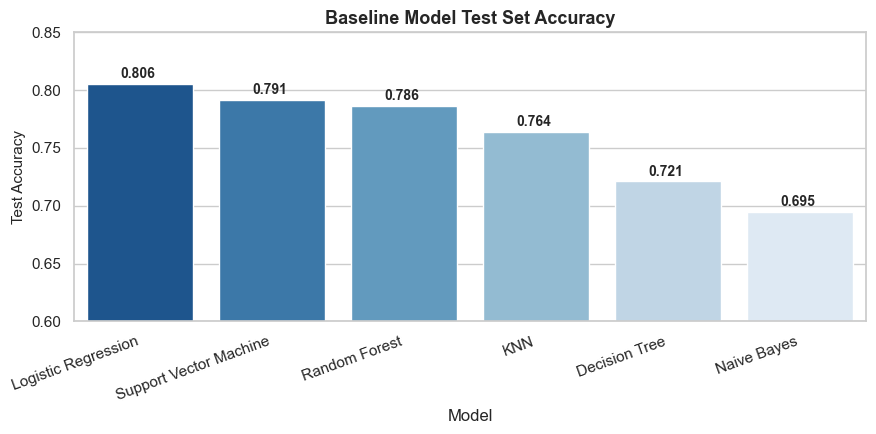

In [5]:
plt.figure(figsize=(9, 4.5))
ax = sns.barplot(data=results_df, x="Model", y="Accuracy", palette="Blues_r")
plt.title("Baseline Model Test Set Accuracy", fontsize=13, fontweight="bold")
plt.ylabel("Test Accuracy", fontsize=11)
plt.ylim(0.60, 0.85)
plt.xticks(rotation=20, ha="right")

for p in ax.patches:
    ax.annotate(f"{p.get_height():.3f}", (p.get_x() + 0.25, p.get_height() + 0.005),
                fontweight="bold", fontsize=10)

plt.tight_layout()
plt.show()

## 5. Model Serialization & Export

In [6]:
models_dir = Path("../models")
reports_dir = Path("../reports")
models_dir.mkdir(parents=True, exist_ok=True)
reports_dir.mkdir(parents=True, exist_ok=True)

# Save baseline model artifacts
for name, model in trained_models.items():
    filename = name.lower().replace(" ", "_") + ".pkl"
    joblib.dump(model, models_dir / filename)

# Save reports
results_df.to_csv(reports_dir / "model_training_results.csv", index=False)
cv_df.to_csv(reports_dir / "cross_validation_results.csv", index=False)
print("All 6 baseline models and training reports saved successfully.")

All 6 baseline models and training reports saved successfully.


## Summary & Next Step
- Logistic Regression and Random Forest lead in baseline cross-validated F1-score (~0.59) and Accuracy (~0.80).
- Naive Bayes shows the highest Recall (0.84) but low Precision (0.46).
- Next, we conduct comprehensive churn-focused evaluation in `06_Model_Evaluation.ipynb`.